# Case Study 2 — "When Will the Food Be Ready?": Preparation-Time Prediction with Noisy Labels, and What It Does to Rider Dispatch

**Priority:** ★★ Good to have · **Reference:** Case Study 2 — *Zomato food preparation time (FPT) prediction, with Swiggy just-in-time dispatch* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Delivery Operations, Logistics Product, Restaurant Partnerships, Finance
**Data:** ⚠️ **SYNTHETIC** (D-2-01). Kitchen-level order timestamps are confidential; this is a calibrated simulation with hidden true food-ready times.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs02_prep_time_dispatch.ipynb`

## 0. Executive Summary for Business

«EXEC»

## 1. The Problem in Simple English

When you order food, the app must guess **how long the kitchen will take**. That guess does two jobs. It is part of the delivery time shown to the customer. It also decides **when to send the rider**. Send the rider too early and the rider stands outside the restaurant, wasting paid time that could have been another delivery. Send the rider too late and the food sits and gets cold, and the customer waits.

The twist is that the **label is dirty**. The easy way to record "preparation time" is the time from the restaurant accepting the order to the rider picking it up. But if the rider arrives before the food is ready, pick-up waits for the food (good label). If the rider arrives **after** the food is ready, pick-up time is really the rider's arrival, not the kitchen's speed (bad label). A model trained on that label learns rider behaviour, not cooking.

Leaders and interviewers want to know:
1. How **wrong** is the pick-up label, and for which orders?
2. If restaurants press a **"Food Order Ready" button**, is that label good enough, given that many will not press it?
3. How accurate can a model be, and does the **choice of label matter more than the choice of model**?
4. Because being late and being early **cost different amounts**, how should the prediction be turned into a **dispatch time**?
5. How much money is at stake, and how would we prove it in an experiment?

## 2. Reference from the Case File

### (a) What Zomato and Swiggy documented

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Zomato: accurate time estimates matter because a higher-than-actual estimate "can deter customers from ordering" and a lower one "can then increase inflow to our customer support". FPT is one part, with rider pick-up and drop time |
| Data and features | Order items (about 3.5 million distinct dishes), restaurant identity (150k+ restaurants in a month), kitchen state (running orders, up to the last 5 completed orders, opening hours) |
| Models | Word2Vec item embeddings, entity embeddings for restaurants, an XGBoost regressor, then a stacked LSTM plus dense network over the last 5 completed and up to 5 running orders |
| Company-claimed result (2020) | Mean absolute error from 4.64 to 4.13 minutes and mean squared error from 32 to 28 (the page presents this as against the previous architecture) |
| Label fix | The old label (accepted to rider pick-up) included rider behaviour, so Zomato added a restaurant-marked "Food Order Ready" (FOR) button; initial results: "9 percent improvement within 5 minutes accuracy" |
| Dispatch (Swiggy, 2019) | Naive just-in-time rule: delay assignment by estimated prep time minus average first-mile time; a refinement earmarks a rider but dispatches just in time so assignments can be swapped. Risks named: rider rejection after a delay, prep over-estimate (food sits), first-mile under-estimate. No quantified result |
| Evidence limits | No hypothesis tests or intervals; validation split not described; dispatch efficiency gains **not disclosed** |

**Sources:** Zomato blog "The Deep Tech Behind Estimating Food Preparation Time" (Deepankar Pal, Feb 4, 2020); Swiggy Bytes "The Swiggy Delivery Challenge Part Two" (May 8, 2019) and the Aug 2023 cart post.

**Evidence note:** the prep-time model is strongly documented; the dispatch effect is documented only as logic and trade-offs. Public method detail is thin, so this notebook is an interview-standard solution on simulated data, not a reproduction of either company's system. We do not build the LSTM or Word2Vec parts.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 250 restaurants (4 types), about 150,000 orders over 60 days. A hidden true food-ready time depends on dish, order size, restaurant type and speed, kitchen load, peak hour, rain |
| Labels | **Pick-up label** (old): the later of food ready and rider arrival, plus handover. **FOR label**: pressed on about half of the orders (less when the kitchen is busy); some presses are made at pick-up. A few glitchy timestamps |
| Methods compared | (0) global median; (1) restaurant mean; (2) ridge; (3) gradient boosting on the pick-up label; (4) gradient boosting on the FOR label only; (5) gradient boosting on FOR where pressed and the pick-up label otherwise |
| Statistics added | Label bias and censoring tests; FOR selection-bias tests; paired tests (Wilcoxon, McNemar, bootstrap, Holm) against the **hidden truth**; calibration by true prep time; heteroscedasticity; segment errors with multiple-testing control; dispatch cost simulation with **asymmetric cost** and a newsvendor check; A/B sample size with clustering |

### (c) How the industry uses this

Every Indian delivery app combines a prep-time estimate with a rider assignment engine. Cloud kitchens, quick-service chains and dine-in restaurants behave very differently, which is why restaurant identity and kitchen load matter. "Food ready" buttons, kitchen display screens and now sensor data are all attempts to fix the label. It is a common interview case because it joins a **modelling** question (noisy labels), a **decision** question (what to do with a prediction when errors have different costs) and an **experimentation** question.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | When should we send the rider, so that the rider arrives just as the food is ready, at the lowest total cost of waiting? |
| Analytical | How biased is the pick-up label, does the FOR label fix it, which model predicts the true food-ready time best, and how much does it save to dispatch on a deliberately **high** quantile rather than the average? |

**Hypotheses**
- **H1:** H0: the pick-up label is unbiased for the true food-ready time (paired Wilcoxon and t-test); and the bias is the same for quick and slow dishes.
- **H2 (FOR coverage):** H0: restaurants press FOR on a random subset of orders (test press rate vs kitchen load and type; compare true prep time of pressed vs unpressed orders).
- **H3:** H0: gradient boosting equals the restaurant-mean baseline in absolute error against the truth (paired Wilcoxon).
- **H4 (label vs model):** H0: a model trained on the FOR label is no better than one trained on the pick-up label at being within 5 minutes of the truth (McNemar; Holm across comparisons).
- **H5 (dispatch):** H0: just-in-time dispatch at the best quantile has the same expected waiting cost as dispatching at once; and the best quantile is close to the newsvendor ratio cost_late / (cost_late + cost_early).

**Primary metrics:** MAE and "within 5 minutes" accuracy **against the hidden true time** (what really matters) and against the observed label (what a team would see). **Decision metric:** waiting cost in ₹ per order (rider waiting minutes × ₹ per minute + food waiting minutes × ₹ per minute).

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
T_START = time.time()
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public kitchen-level order timestamps from Indian delivery apps | **None.** Zomato and Swiggy publish method posts but no order-level data. Public delivery datasets (for example Kaggle food-delivery sets) have a total delivery time per order but no kitchen-ready time and no rider arrival, so the label problem cannot be studied |
| **Decision** | Synthetic orders with hidden true food-ready time and rider arrival, so that labels can be scored against the truth and dispatch policies can be simulated (D-2-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs02.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 2 (Zomato food preparation time and rider dispatch)
========================================================================================
THIS DATA IS SYNTHETIC. Kitchen-level order timestamps are confidential.

Documented context (Zomato blog, Feb 2020; Swiggy Bytes 2019, 2023): FPT label was restaurant-accepted to rider
pick-up, so it includes rider behaviour; a restaurant-marked "Food Order Ready" (FOR) button gives a cleaner label
(company-claimed 9% gain in within-5-minutes accuracy); features are order items, restaurant, kitchen state (running
orders, last completed orders); naive just-in-time dispatch delays assignment by (prep time - first-mile time).

Simulation: 250 restaurants, ~150,000 orders over 60 days.
  * True food-ready time (hidden) = dish base time x restaurant type x restaurant speed x load x peak x noise.
  * Old label (pick-up) = max(food ready, rider arrival under dispatch-at-once) + handover: censored below by the rider.
  * FOR label: pressed on only part of the orders (compliance falls with kitchen load); some presses are made at pick-up.
  * Rider first-mile (incl. assignment) is random and larger in rain and at peaks.
Outputs: orders.csv.gz, restaurants.csv.gz (columns starting with "_" are hidden truth, for the digital twin only).
"""
import numpy as np
import pandas as pd

SEED = 42
N_R, DAYS, N_ORD = 250, 60, 150_000
START = pd.Timestamp("2026-03-01")
TYPES = ["cloud kitchen", "quick service", "casual dining", "fine dining"]
TYPE_MULT = {"cloud kitchen": 0.90, "quick service": 0.85, "casual dining": 1.05, "fine dining": 1.20}
TYPE_CAP = {"cloud kitchen": (3, 6), "quick service": (2, 5), "casual dining": (2, 4), "fine dining": (1, 3)}
TYPE_FOR = {"cloud kitchen": 0.75, "quick service": 0.55, "casual dining": 0.35, "fine dining": 0.22}
GROUPS = ["beverage", "snacks", "roll/wrap", "burger", "pizza", "biryani", "north indian", "chinese", "south indian", "dessert", "thali", "grill"]
BASE_MIN = np.array([4, 8, 9, 10, 15, 14, 16, 15, 11, 6, 17, 22], float)


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    typ = rng.choice(len(TYPES), N_R, p=[0.30, 0.30, 0.28, 0.12]); tname = np.array(TYPES)[typ]
    cap = np.array([rng.integers(*TYPE_CAP[t]) for t in tname]); speed = np.exp(rng.normal(0, 0.18, N_R)); sigma = rng.uniform(0.12, 0.30, N_R)
    comp = np.clip(np.array([TYPE_FOR[t] for t in tname]) + rng.normal(0, 0.12, N_R), 0.03, 0.95); gaming = rng.beta(1.2, 6, N_R)
    cuis = rng.choice(len(GROUPS), (N_R, 2), p=np.array([0.04, 0.10, 0.08, 0.09, 0.09, 0.10, 0.14, 0.09, 0.08, 0.04, 0.08, 0.07]))
    vol = np.exp(rng.normal(0, 1.05, N_R)) * np.array([1.3 if t == "cloud kitchen" else 1.0 for t in tname]); vol /= vol.sum()
    rest = pd.DataFrame({"restaurant_id": np.arange(N_R), "rest_type": tname, "kitchen_capacity": cap, "cuisine_group": [GROUPS[c] for c in cuis[:, 0]],
                         "_speed": speed, "_noise_sigma": sigma, "_for_compliance": comp, "_for_gaming_rate": gaming})
    r = rng.choice(N_R, N_ORD, p=vol); day = rng.integers(0, DAYS, N_ORD)
    hw = np.array([1, 0.5, 0.3, 0.2, 0.2, 0.4, 1, 2, 3, 3, 3, 5, 9, 9, 6, 3, 2, 3, 5, 8, 10, 9, 6, 3], float); hw = hw / hw.sum()
    hour = rng.choice(24, N_ORD, p=hw); sec = hour * 3600 + rng.integers(0, 3600, N_ORD); dow = day % 7; rain_day = rng.random(DAYS) < 0.2; rain = rain_day[day].astype(int)
    ts = START + pd.to_timedelta(day, unit="D") + pd.to_timedelta(sec, unit="s")
    df = pd.DataFrame({"restaurant_id": r, "day": day, "hour": hour, "dow": dow, "rain": rain, "order_ts": ts, "_sec": day * 86400 + sec}).sort_values(["restaurant_id", "_sec"]).reset_index(drop=True)
    key = df.restaurant_id.values.astype(np.int64) * 10**8 + df._sec.values; idx = np.arange(N_ORD); q = idx - np.searchsorted(key, key - 900, side="left")
    df["_qlen"] = q; df["running_orders"] = np.minimum(q, 5)
    rr = df.restaurant_id.values; grp = np.where(rng.random(N_ORD) < 0.7, cuis[rr, 0], cuis[rr, 1]); n_items = np.minimum(1 + rng.poisson(1.1, N_ORD), 8)
    df["rest_type"] = tname[rr]; df["kitchen_capacity"] = cap[rr]; df["cuisine_group"] = rest.cuisine_group.values[rr]
    df["dish_group"] = np.array(GROUPS)[grp]; df["n_items"] = n_items; df["order_value_inr"] = np.round(np.maximum(40, n_items * np.exp(rng.normal(np.log(190), 0.35, N_ORD)) * (1 + 0.35 * (tname[rr] == "fine dining"))), 0)
    peak = ((hour >= 12) & (hour <= 14)) | ((hour >= 19) & (hour <= 22)); df["_peak"] = peak.astype(int)
    mu = BASE_MIN[grp] * np.array([TYPE_MULT[t] for t in tname])[rr] * speed[rr] * (1 + 0.14 * (n_items - 1) ** 0.8) * (1 + 0.16 * q / cap[rr]) * (1 + 0.08 * peak) * (1 + 0.04 * rain) * (1 + 0.03 * (dow >= 5))
    df["_true_fpt_min"] = np.maximum(2.0, mu * np.exp(rng.normal(0, 1, N_ORD) * sigma[rr] - sigma[rr] ** 2 / 2) + 0.8)
    fm_det = 6.0 * (1 + 0.15 * peak) * (1 + 0.20 * rain); df["_first_mile_min"] = fm_det * np.exp(rng.normal(0, 0.45, N_ORD)) + 1.0
    df["est_first_mile_min"] = np.round((fm_det * np.exp(0.1) + 1.0) * np.exp(rng.normal(0, 0.12, N_ORD)), 1)
    pick = np.maximum(df._true_fpt_min.values, df._first_mile_min.values) + rng.exponential(0.7, N_ORD); df["pickup_label_min"] = pick
    p_press = comp[rr] * (1 - 0.07 * np.minimum(q, 5)); pressed = rng.random(N_ORD) < np.clip(p_press, 0, 1); gm = rng.random(N_ORD) < gaming[rr]
    honest = np.maximum(1.0, df._true_fpt_min.values + rng.normal(0, 1.0, N_ORD)); df["for_label_min"] = np.where(pressed, np.where(gm, pick, honest), np.nan); df["_for_gamed"] = (pressed & gm).astype(int)
    # data-quality defects: glitchy timestamps, duplicates, missing values
    g = rng.random(N_ORD) < 0.004; df.loc[g, "pickup_label_min"] = rng.choice([0.2, 0.5, 150.0, 240.0, 600.0], g.sum())
    miss = rng.random(N_ORD) < 0.015; df.loc[miss, "order_value_inr"] = np.nan
    df = df.drop(columns="_sec"); df = pd.concat([df, df.sample(n=800, random_state=seed)], ignore_index=True).sort_values(["order_ts", "restaurant_id"]).reset_index(drop=True)
    df.insert(0, "order_id", np.arange(len(df)))
    for c in ("pickup_label_min", "for_label_min", "_true_fpt_min", "_first_mile_min"): df[c] = df[c].round(2)
    return df, rest

Overwriting data/generate_cs02.py


In [3]:
os.makedirs("data/cs02", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs02 as gen; importlib.reload(gen)
t0 = time.time(); raw, rest = gen.generate(seed=SEED); raw.to_csv("data/cs02/orders.csv.gz", index=False); rest.to_csv("data/cs02/restaurants.csv.gz", index=False)
print(f"{len(raw):,} order rows | {raw.restaurant_id.nunique()} restaurants | generated in {time.time() - t0:.0f}s")
raw.head(4)

150,800 order rows | 250 restaurants | generated in 35s


,order_id,restaurant_id,day,hour,dow,rain,order_ts,_qlen,running_orders,rest_type,kitchen_capacity,cuisine_group,dish_group,n_items,order_value_inr,_peak,_true_fpt_min,_first_mile_min,est_first_mile_min,pickup_label_min,for_label_min,_for_gamed
0,0,37,0,0,0,0,2026-03-01 00:01:26,0,0,quick service,2,pizza,pizza,1,220.000,1,12.070,6.720,10.100,12.240,NaN,0
1,1,37,0,0,0,0,2026-03-01 00:05:29,1,1,quick service,2,pizza,pizza,1,214.000,1,19.520,3.750,7.800,20.370,20.370,1
2,2,119,0,0,0,0,2026-03-01 00:10:39,0,0,casual dining,2,north indian,burger,2,392.000,1,11.680,13.110,9.700,15.970,15.970,1
3,3,132,0,0,0,0,2026-03-01 00:12:13,0,0,quick service,3,north indian,north indian,2,432.000,0,17.300,7.310,7.700,17.660,NaN,0


| Parameter | Value | Basis |
|---|---|---|
| Scale | 250 restaurants, about 150,000 orders, 60 days | Our assumption (Zomato: 150k+ restaurants a month) |
| Restaurant types | Cloud kitchen 30%, quick service 30%, casual dining 28%, fine dining 12%; fine dining slowest | Our assumption; the case file says restaurant traits such as delivery-only vs fine dining matter |
| True prep time | Mean about 16 minutes; depends on dish group, items, type, kitchen load, peak, rain | Our assumption (Swiggy's example uses 15 minutes) |
| Kitchen state | Running orders in the last 15 minutes (cap 5), previous completed orders | **Documented** feature family (running orders, last completed orders) |
| Rider first mile | Mean about 8.5 minutes including assignment, larger in rain and at peaks | Our assumption (Swiggy's example uses 5 minutes) |
| Old label | Later of food ready and rider arrival under dispatch-at-once, plus handover | **Documented** problem (label includes rider pick-up behaviour) |
| FOR label | Pressed on about half of orders; press rate falls with kitchen load; about 14% of presses made at pick-up | Our assumption; compliance as a data-quality issue is noted in the case file |
| DQ issues | 800 duplicate rows, about 0.4% impossible timestamps, 1.5% missing order value | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("order_id, restaurant_id, order_ts, day, hour, dow", "Order, restaurant, acceptance time, day 0 to 59, hour, day of week"),
    ("rest_type, kitchen_capacity, cuisine_group", "Restaurant type, rated kitchen capacity (1 to 6), main cuisine"),
    ("dish_group, n_items, order_value_inr", "Main dish group of the order, number of items, basket value"),
    ("running_orders", "Orders accepted by the same restaurant in the previous 15 minutes (capped at 5)"),
    ("rain", "1 if it rained that day"),
    ("est_first_mile_min", "Dispatch system's estimate of rider assignment plus first-mile time"),
    ("pickup_label_min", "OLD LABEL: acceptance to rider pick-up (includes rider behaviour; contains glitches)"),
    ("for_label_min", "FOR LABEL: acceptance to restaurant pressing Food Order Ready (missing if not pressed)"),
    ("_true_fpt_min, _first_mile_min, _for_gamed, _qlen, _peak", "HIDDEN truth: real food-ready time, real rider first-mile, FOR pressed at pick-up, uncapped queue, peak flag (never used as model features)"),
    ("restaurants: _speed, _noise_sigma, _for_compliance, _for_gaming_rate", "HIDDEN restaurant traits (digital twin only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs02/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"order_id, restaurant_id, order_ts, day, hour, dow","Order, restaurant, acceptance time, day 0 to 5..."
1,"rest_type, kitchen_capacity, cuisine_group","Restaurant type, rated kitchen capacity (1 to ..."
2,"dish_group, n_items, order_value_inr","Main dish group of the order, number of items,..."
3,running_orders,Orders accepted by the same restaurant in the ...
4,rain,1 if it rained that day
5,est_first_mile_min,Dispatch system's estimate of rider assignment...
6,pickup_label_min,OLD LABEL: acceptance to rider pick-up (includ...
7,for_label_min,FOR LABEL: acceptance to restaurant pressing F...
8,"_true_fpt_min, _first_mile_min, _for_gamed, _q...","HIDDEN truth: real food-ready time, real rider..."
9,"restaurants: _speed, _noise_sigma, _for_compli...",HIDDEN restaurant traits (digital twin only)


## 5. Data Quality Checks

In [5]:
cols = [c for c in raw.columns if c != "order_id"]
checks = {"duplicate orders": int(raw.duplicated(cols).sum()), "impossible pick-up label (< 1 or > 120 min)": int(((raw.pickup_label_min < 1) | (raw.pickup_label_min > 120)).sum()),
          "missing order value": int(raw.order_value_inr.isna().sum()), "orders with FOR pressed": int(raw.for_label_min.notna().sum())}
print(pd.Series(checks, name="rows").to_string())
df = raw.drop_duplicates(cols); df = df[(df.pickup_label_min >= 1) & (df.pickup_label_min <= 120)].copy()
df["order_value_inr"] = df.order_value_inr.fillna(df.order_value_inr.median())
df = df.sort_values(["restaurant_id", "order_ts"]).reset_index(drop=True)
df["last5_mean"] = df.groupby("restaurant_id")["pickup_label_min"].transform(lambda s: s.shift(1).rolling(5, min_periods=2).mean())
df["gap_prev_min"] = (df.groupby("restaurant_id")["order_ts"].diff().dt.total_seconds() / 60).clip(upper=180)
print(f"\nClean: {len(df):,} orders | FOR pressed on {df.for_label_min.notna().mean():.1%} | missing last-5 history: {df.last5_mean.isna().mean():.1%} | mean true FPT {df._true_fpt_min.mean():.1f} min | mean pick-up label {df.pickup_label_min.mean():.1f} min")
print(f"Orders per restaurant: median {df.groupby('restaurant_id').size().median():.0f}, min {df.groupby('restaurant_id').size().min()}, max {df.groupby('restaurant_id').size().max()}")

duplicate orders                                 800
impossible pick-up label (< 1 or > 120 min)      628
missing order value                             2189
orders with FOR pressed                        77854



Clean: 149,373 orders | FOR pressed on 51.6% | missing last-5 history: 0.3% | mean true FPT 16.1 min | mean pick-up label 17.3 min
Orders per restaurant: median 338, min 12, max 5196


**Observation:** «O5»

## 6. Exploratory Data Analysis

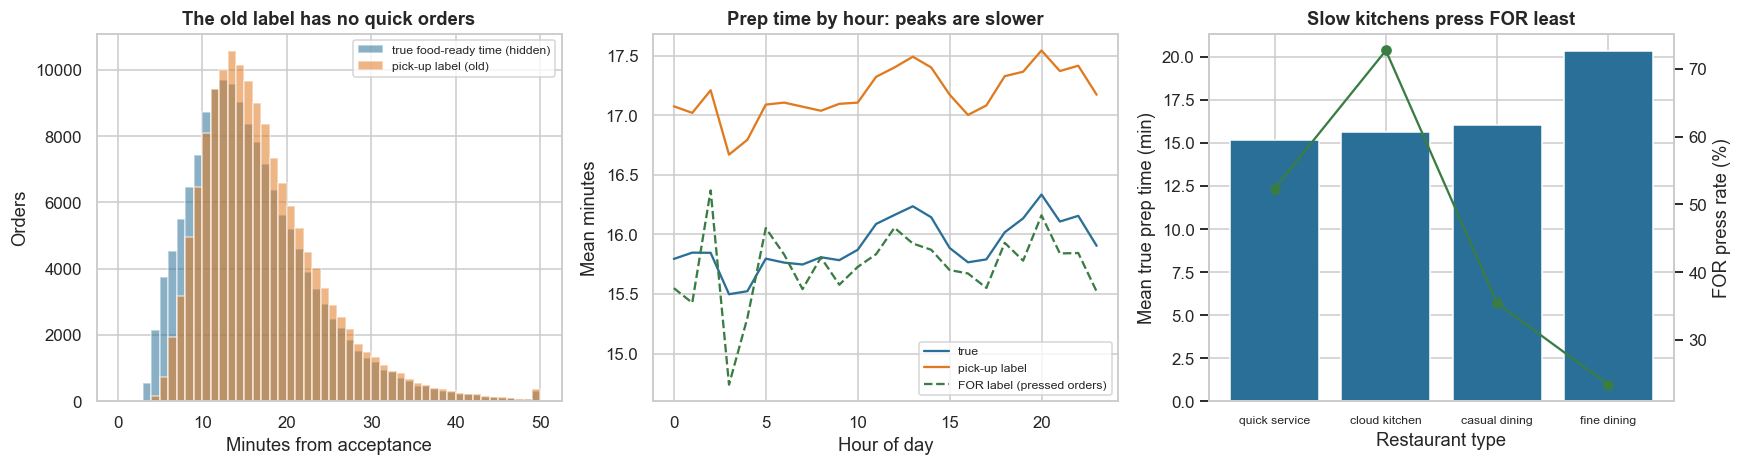

                true  press
rest_type                  
quick service 15.189  0.524
cloud kitchen 15.652  0.727
casual dining 16.064  0.354
fine dining   20.326  0.234
Share of orders where the rider (dispatched at once) arrives after the food is ready: 15.8%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
bins = np.arange(0, 51, 1)
axes[0].hist(df._true_fpt_min.clip(upper=50), bins=bins, alpha=0.55, color="#2a6f97", label="true food-ready time (hidden)"); axes[0].hist(df.pickup_label_min.clip(upper=50), bins=bins, alpha=0.55, color="#e07a1f", label="pick-up label (old)")
axes[0].set_xlabel("Minutes from acceptance"); axes[0].set_ylabel("Orders"); axes[0].set_title("The old label has no quick orders"); axes[0].legend(fontsize=8)
hh = df.groupby("hour").agg(true=("_true_fpt_min", "mean"), pick=("pickup_label_min", "mean"), forl=("for_label_min", "mean"))
axes[1].plot(hh.index, hh.true, color="#2a6f97", label="true"); axes[1].plot(hh.index, hh.pick, color="#e07a1f", label="pick-up label"); axes[1].plot(hh.index, hh.forl, color="#3a7d44", ls="--", label="FOR label (pressed orders)")
axes[1].set_xlabel("Hour of day"); axes[1].set_ylabel("Mean minutes"); axes[1].set_title("Prep time by hour: peaks are slower"); axes[1].legend(fontsize=8)
tt = df.groupby("rest_type").agg(true=("_true_fpt_min", "mean"), press=("for_label_min", lambda s: s.notna().mean())).sort_values("true")
axes[2].bar(tt.index, tt.true, color="#2a6f97"); ax2 = axes[2].twinx(); ax2.plot(tt.index, tt.press * 100, "o-", color="#3a7d44"); ax2.set_ylabel("FOR press rate (%)"); ax2.grid(False)
axes[2].set_xlabel("Restaurant type"); axes[2].set_ylabel("Mean true prep time (min)"); axes[2].set_title("Slow kitchens press FOR least"); axes[2].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()
print(tt.round(3).to_string()); print(f"Share of orders where the rider (dispatched at once) arrives after the food is ready: {(df._first_mile_min > df._true_fpt_min).mean():.1%}")

**Takeaway:** «O61»

## 7. Statistical Analysis (core section)

### 7.1 How wrong is the pick-up label? (H1)

**(a) Why?** The pick-up label is the later of two events: food ready and rider arrival. When the rider is late, the label equals the rider's arrival, so quick dishes get a label that is **too long**. We use the hidden truth to measure this: mean bias with a paired t-test and Wilcoxon test, then bias by true prep-time band, then the same for the FOR label.

#### Code

In [7]:
bias = df.pickup_label_min - df._true_fpt_min; cens = df._first_mile_min > df._true_fpt_min; n = len(df)
se = bias.std() / np.sqrt(n); w = stats.wilcoxon(df.pickup_label_min, df._true_fpt_min)
print(f"Pick-up label minus truth: mean {bias.mean():+.2f} min (95% CI {bias.mean() - 1.96 * se:+.2f} to {bias.mean() + 1.96 * se:+.2f}); median {bias.median():+.2f}; Wilcoxon p = {w.pvalue:.2g}; correlation with truth {np.corrcoef(df.pickup_label_min, df._true_fpt_min)[0, 1]:.3f}")
bk = pd.cut(df._true_fpt_min, [0, 8, 12, 16, 20, 30, 200], labels=["< 8", "8-12", "12-16", "16-20", "20-30", "30+"])
tab = pd.DataFrame({"orders": bk.value_counts().sort_index(), "mean true FPT": df.groupby(bk)["_true_fpt_min"].mean(), "mean pick-up label": df.groupby(bk)["pickup_label_min"].mean(),
                    "bias (label - true)": bias.groupby(bk).mean(), "share rider-censored": cens.groupby(bk).mean()})
F, p_anova = stats.f_oneway(*[bias[bk == b].values for b in tab.index])
print(f"Bias differs across prep-time bands: ANOVA F = {F:.0f}, p = {p_anova:.2g}")
pr = df[df.for_label_min.notna()]; bf = pr.for_label_min - pr._true_fpt_min; gamed = pr._for_gamed == 1; proxy = np.isclose(pr.for_label_min, pr.pickup_label_min, atol=0.011)
print(f"FOR label minus truth (pressed orders): mean {bf.mean():+.2f} min; MAE vs truth {bf.abs().mean():.2f} min | honest presses only: mean {bf[~gamed].mean():+.2f}, MAE {bf[~gamed].abs().mean():.2f} | presses made at pick-up: {gamed.mean():.1%} (visible as FOR = pick-up: {proxy.mean():.1%})")
tab.round(3)

Pick-up label minus truth: mean +1.25 min (95% CI +1.24 to +1.26); median +0.61; Wilcoxon p = 0; correlation with truth 0.965


Bias differs across prep-time bands: ANOVA F = 5751, p = 0
FOR label minus truth (pressed orders): mean +0.21 min; MAE vs truth 0.87 min | honest presses only: mean +0.00, MAE 0.80 | presses made at pick-up: 16.4% (visible as FOR = pick-up: 17.0%)


,orders,mean true FPT,mean pick-up label,bias (label - true),share rider-censored
_true_fpt_min,,,,,
< 8,16592,6.268,9.610,3.342,0.691
8-12,32086,10.175,11.701,1.526,0.258
12-16,36657,13.940,14.909,0.970,0.082
16-20,26941,17.860,18.637,0.777,0.025
20-30,29353,23.790,24.504,0.714,0.005
30+,7744,36.120,36.820,0.699,0.001


**Observation:** «O71»

### 7.2 Who presses the FOR button? Selection bias (H2)

**(a) Why?** A FOR-only model is trained only on orders where the button was pressed. If pressing depends on how busy the kitchen is or on the restaurant type, those orders are **not a random sample**. We test (i) press rate by running orders and type, (ii) a logistic regression of pressing on kitchen load, type and peak, (iii) whether true prep time differs between pressed and unpressed orders (Welch t-test and Cohen's d).

#### Code

In [8]:
df["pressed"] = df.for_label_min.notna().astype(int); df["peak"] = df.hour.isin([12, 13, 14, 19, 20, 21, 22]).astype(int)
print(df.groupby("running_orders").agg(orders=("pressed", "size"), press_rate=("pressed", "mean"), mean_true_fpt=("_true_fpt_min", "mean")).round(3).T.to_string())
lg = smf.logit("pressed ~ running_orders + peak + n_items + C(rest_type)", data=df).fit(disp=0)
ci = lg.conf_int().loc["running_orders"]; print(f"Logistic: odds ratio per extra running order {np.exp(lg.params['running_orders']):.3f} (95% CI {np.exp(ci[0]):.3f} to {np.exp(ci[1]):.3f}), p = {lg.pvalues['running_orders']:.2g}")
print("Odds ratios by type (vs cloud kitchen):", {k.split('T.')[1].rstrip(']'): round(float(np.exp(v)), 2) for k, v in lg.params.items() if 'rest_type' in k})
a, b_ = df[df.pressed == 1]._true_fpt_min, df[df.pressed == 0]._true_fpt_min; t_ = stats.ttest_ind(a, b_, equal_var=False); sp = np.sqrt((a.var() + b_.var()) / 2)
print(f"True prep time: pressed {a.mean():.2f} vs unpressed {b_.mean():.2f} min; Welch t = {t_.statistic:.1f}, p = {t_.pvalue:.2g}; Cohen's d = {(a.mean() - b_.mean()) / sp:+.3f}")
rp = df.groupby("restaurant_id").pressed.mean(); print(f"Restaurants with a press rate under 10%: {(rp < 0.10).mean():.1%}; over 80%: {(rp > 0.80).mean():.1%}; spread (sd) of press rate across restaurants {rp.std():.2f}")
print(f"Orders with FOR pressed that came from busy kitchens (3+ running): {df[df.pressed == 1].running_orders.ge(3).mean():.1%} vs {df.running_orders.ge(3).mean():.1%} of all orders")

running_orders           0          1         2         3       4       5
orders         106,345.000 30,146.000 8,748.000 2,780.000 909.000 445.000
press_rate           0.534      0.493     0.455     0.373   0.365   0.285
mean_true_fpt       15.903     16.494    16.605    16.168  16.413  15.921


Logistic: odds ratio per extra running order 0.847 (95% CI 0.835 to 0.859), p = 3.9e-114
Odds ratios by type (vs cloud kitchen): {'cloud kitchen': 4.78, 'fine dining': 0.54, 'quick service': 2.03}
True prep time: pressed 15.64 vs unpressed 16.53 min; Welch t = -22.7, p = 1.6e-113; Cohen's d = -0.118
Restaurants with a press rate under 10%: 2.0%; over 80%: 8.0%; spread (sd) of press rate across restaurants 0.21


Orders with FOR pressed that came from busy kitchens (3+ running): 1.9% vs 2.8% of all orders


**Observation:** «O72»

### 7.3 Five models, scored against the truth and against the label (H3, H4)

**Split (time-ordered):** days 0 to 41 train, days 42 to 49 validation (used only in 7.7), days 50 to 59 test. The feature set is what a live system would know at acceptance: restaurant, type, rated capacity, dish group, items, order value, running orders, hour, weekday, rain, mean of the last 5 pick-up labels at the restaurant and the gap since the previous order. (The last-5 mean uses the previous orders' labels without checking they had finished; a live system must.)

| # | Method | Target |
|---|---|---|
| 0 | Global median | pick-up label |
| 1 | Restaurant mean (shrunk to type mean, weight 10 orders) | pick-up label |
| 2 | Ridge regression (one-hot restaurant, dish, type + numeric) | pick-up label |
| 3 | Gradient boosting (200 trees, defaults) | **pick-up label** |
| 4 | Gradient boosting, same features | **FOR label**, pressed orders only |
| 5 | Gradient boosting, same features | FOR where pressed, else pick-up label |

No tuning (per the brief). We report MAE, RMSE, within-5-minutes accuracy and bias against the **truth** and against the **pick-up label**.

#### Code

In [9]:
tr = df.day < 42; va = (df.day >= 42) & (df.day < 50); te = df.day >= 50
Xd = pd.DataFrame({"restaurant_id": df.restaurant_id.values, "rest_type": df.rest_type.astype("category").cat.codes.values, "dish_group": df.dish_group.astype("category").cat.codes.values,
                   "kitchen_capacity": df.kitchen_capacity.values, "n_items": df.n_items.values, "order_value_inr": df.order_value_inr.values, "running_orders": df.running_orders.values,
                   "hour": df.hour.values, "dow": df.dow.values, "rain": df.rain.values, "last5_mean": df.last5_mean.values, "gap_prev_min": df.gap_prev_min.values})
CATS = ["restaurant_id", "rest_type", "dish_group"]; truth = df._true_fpt_min.values; lab = df.pickup_label_min.values; forl = df.for_label_min.values
def hgb(): return HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1, categorical_features=CATS, random_state=SEED)
PV, PT = {}, {}
def store(name, pred_va, pred_te): PV[name], PT[name] = np.asarray(pred_va, float), np.asarray(pred_te, float)
t0 = time.time(); M0 = np.median(lab[tr]); store("0 global median", np.full(va.sum(), M0), np.full(te.sum(), M0))
tm = df[tr].groupby("rest_type").pickup_label_min.mean(); g = df[tr].groupby("restaurant_id").pickup_label_min.agg(["sum", "count"]); typ_of = df.groupby("restaurant_id").rest_type.first()
rm = ((g["sum"] + 10 * typ_of.reindex(g.index).map(tm)) / (g["count"] + 10)).reindex(range(gen.N_R)); rm = rm.fillna(typ_of.map(tm))
store("1 restaurant mean", df[va].restaurant_id.map(rm).values, df[te].restaurant_id.map(rm).values)
ct = ColumnTransformer([("oh", OneHotEncoder(handle_unknown="ignore"), CATS), ("num", make_pipeline(__import__("sklearn.impute", fromlist=["SimpleImputer"]).SimpleImputer(strategy="median"), StandardScaler()), [c for c in Xd.columns if c not in CATS])])
rg = make_pipeline(ct, Ridge(alpha=10.0)).fit(Xd[tr], lab[tr]); store("2 ridge", rg.predict(Xd[va]), rg.predict(Xd[te]))
m3 = hgb().fit(Xd[tr], lab[tr]); store("3 boosting, pick-up label", m3.predict(Xd[va]), m3.predict(Xd[te]))
trf = tr & ~np.isnan(forl); m4 = hgb().fit(Xd[trf], forl[trf]); store("4 boosting, FOR label", m4.predict(Xd[va]), m4.predict(Xd[te]))
y5 = np.where(np.isnan(forl), lab, forl); m5 = hgb().fit(Xd[tr], y5[tr]); store("5 boosting, FOR else pick-up", m5.predict(Xd[va]), m5.predict(Xd[te]))
def mt(p, y): e = p - y; return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()), "within 5 min": (np.abs(e) <= 5).mean(), "bias": e.mean()}
rows = []
for k in PT:
    a_, b2 = mt(PT[k], truth[te]), mt(PT[k], lab[te]); rows.append((k, a_["MAE"], a_["RMSE"], a_["within 5 min"], a_["bias"], b2["MAE"], b2["within 5 min"], b2["bias"]))
res = pd.DataFrame(rows, columns=["method", "MAE vs truth", "RMSE vs truth", "within-5 vs truth", "bias vs truth", "MAE vs label", "within-5 vs label", "bias vs label"]).set_index("method")
print(f"Train orders {tr.sum():,} (FOR-labelled {trf.sum():,}) | validation {va.sum():,} | test {te.sum():,} | fitted in {time.time() - t0:.0f}s | test MSE vs truth of the best: {((PT[res['MAE vs truth'].idxmin()] - truth[te]) ** 2).mean():.1f}")
res.round(3)

Train orders 104,454 (FOR-labelled 54,096) | validation 20,058 | test 24,861 | fitted in 730s | test MSE vs truth of the best: 14.5


,MAE vs truth,RMSE vs truth,within-5 vs truth,bias vs truth,MAE vs label,within-5 vs label,bias vs label
method,,,,,,,
0 global median,5.731,7.531,0.528,-0.128,5.360,0.585,-1.381
1 restaurant mean,4.537,5.808,0.629,1.251,4.177,0.693,-0.003
2 ridge,3.161,4.128,0.816,1.237,3.042,0.824,-0.016
"3 boosting, pick-up label",3.094,4.008,0.832,1.230,2.913,0.840,-0.023
"4 boosting, FOR label",2.698,3.809,0.857,0.140,3.025,0.821,-1.113
"5 boosting, FOR else pick-up",2.827,3.819,0.854,0.676,2.903,0.836,-0.577


**Observation:** «O73»

### 7.4 Are the differences real? Paired tests against the truth (H3, H4)

**(a) Why?** All models are scored on the **same test orders**, so the right tests are paired: Wilcoxon signed-rank on the absolute errors, a paired bootstrap interval for the MAE difference (1,000 resamples of orders), and **McNemar** on "within 5 minutes of the truth". Holm correction across the five comparisons.

#### Code

In [10]:
AE = {k: np.abs(PT[k] - truth[te]) for k in PT}; W5 = {k: AE[k] <= 5 for k in PT}; K3, K4, K5, K1, K2 = list(PT)[3], list(PT)[4], list(PT)[5], list(PT)[1], list(PT)[2]
comps = [(K3, K1, "H3: boosting vs restaurant mean"), (K3, K2, "H3: boosting vs ridge"), (K4, K3, "H4: FOR label vs pick-up label"), (K5, K3, "H4: hybrid label vs pick-up label"), (K4, K5, "FOR-only vs hybrid")]
rows = []
for a_, b_, nm in comps:
    d = AE[a_] - AE[b_]; bs = [d[i].mean() for i in (RNG.integers(0, len(d), len(d)) for _ in range(1000))]; x, y = W5[a_], W5[b_]
    mc = mcnemar([[int((x & y).sum()), int((x & ~y).sum())], [int((~x & y).sum()), int((~x & ~y).sum())]], exact=False, correction=True)
    rows.append((nm, d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), stats.wilcoxon(AE[a_], AE[b_]).pvalue, x.mean() - y.mean(), mc.pvalue))
pt = pd.DataFrame(rows, columns=["comparison (first minus second)", "Δ MAE (min)", "CI low", "CI high", "Wilcoxon p", "Δ within-5", "McNemar p"]).set_index("comparison (first minus second)")
pt["p_holm (McNemar)"] = multipletests(pt["McNemar p"], method="holm")[1]; pt["p_holm (Wilcoxon)"] = multipletests(pt["Wilcoxon p"], method="holm")[1]; pt.round(4)

,Δ MAE (min),CI low,CI high,Wilcoxon p,Δ within-5,McNemar p,p_holm (McNemar),p_holm (Wilcoxon)
comparison (first minus second),,,,,,,,
H3: boosting vs restaurant mean,-1.443,-1.480,-1.409,0.000,0.203,0.000,0.000,0.000
H3: boosting vs ridge,-0.068,-0.082,-0.053,0.000,0.016,0.000,0.000,0.000
H4: FOR label vs pick-up label,-0.396,-0.411,-0.379,0.000,0.025,0.000,0.000,0.000
H4: hybrid label vs pick-up label,-0.267,-0.275,-0.258,0.000,0.022,0.000,0.000,0.000
FOR-only vs hybrid,-0.129,-0.141,-0.118,0.000,0.003,0.040,0.040,0.000


**Observation:** «O74»

### 7.5 Calibration by true prep time, and cold-start restaurants

**(a) Why?** A model trained on a label that is too long for quick dishes will **over-predict quick orders** even if its overall error looks fine. We bin test orders by their true prep time and plot the average prediction. The right panel splits error by how many training orders the restaurant has (cold start), and the code afterwards runs a **Breusch-Pagan** test for error variance rising with kitchen load.

#### Code

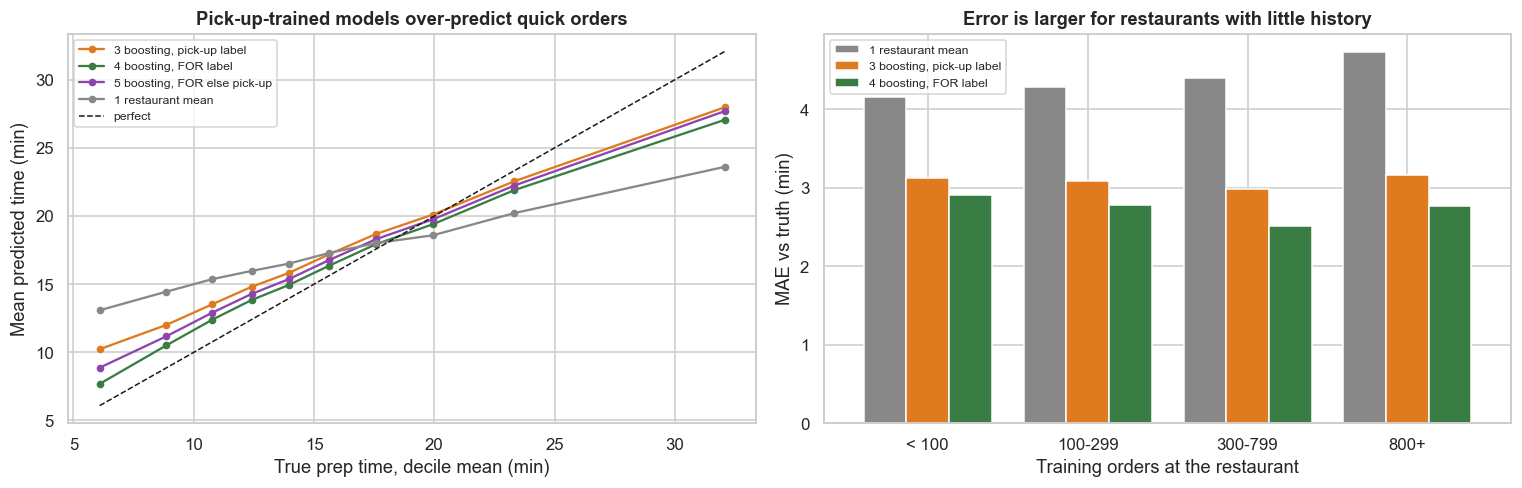

Breusch-Pagan on 4 boosting, FOR label residuals (running orders, items, peak): LM = 227, p = 6.9e-49; residual sd by running orders: 0: 3.74, 1: 3.88, 2: 3.99, 3: 4.52
Test orders per training-volume band: {'< 100': 691, '100-299': 4216, '300-799': 7678, '800+': 12276}
         1 restaurant mean  3 boosting, pick-up label  4 boosting, FOR label
< 100                4.151                      3.126                  2.906
100-299              4.287                      3.081                  2.782
300-799              4.404                      2.980                  2.515
800+                 4.727                      3.168                  2.772


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6)); dte = df[te].reset_index(drop=True); dec = pd.qcut(truth[te], 10, duplicates="drop"); xs = pd.Series(truth[te]).groupby(dec).mean().values
for k, c in ((K3, "#e07a1f"), (K4, "#3a7d44"), (K5, "#8e44ad"), (K1, "#888888")): axes[0].plot(xs, pd.Series(PT[k]).groupby(dec).mean().values, "o-", color=c, label=k, ms=4)
axes[0].plot(xs, xs, "k--", lw=1, label="perfect"); axes[0].set_xlabel("True prep time, decile mean (min)"); axes[0].set_ylabel("Mean predicted time (min)"); axes[0].set_title("Pick-up-trained models over-predict quick orders"); axes[0].legend(fontsize=8)
ntr = df[tr].groupby("restaurant_id").size().reindex(range(gen.N_R), fill_value=0); vb = pd.cut(dte.restaurant_id.map(ntr), [-1, 99, 299, 799, 10 ** 6], labels=["< 100", "100-299", "300-799", "800+"]); cs = {}
for k in (K1, K3, K4): cs[k] = pd.Series(AE[k]).groupby(vb.values).mean()
cs = pd.DataFrame(cs); cs.plot(kind="bar", ax=axes[1], color=["#888888", "#e07a1f", "#3a7d44"], width=0.8); axes[1].set_xlabel("Training orders at the restaurant"); axes[1].set_ylabel("MAE vs truth (min)"); axes[1].set_title("Error is larger for restaurants with little history"); axes[1].legend(fontsize=8); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
res4 = truth[te] - PT[K4]; ex = sm.add_constant(dte[["running_orders", "n_items"]].assign(peak=dte.peak.values).astype(float)); bp = het_breuschpagan(res4, ex)
print(f"Breusch-Pagan on {K4} residuals (running orders, items, peak): LM = {bp[0]:.0f}, p = {bp[1]:.2g}; residual sd by running orders: " + ", ".join(f"{r}: {s:.2f}" for r, s in pd.Series(res4).groupby(dte.running_orders.clip(upper=3).values).std().items()))
print("Test orders per training-volume band:", vb.value_counts().sort_index().to_dict()); print(cs.round(3).to_string())

**Takeaway:** «O75»

### 7.6 Where does the FOR label help most? Segments with multiple-testing control

**(a) Why?** The overall gap between the FOR-trained and pick-up-trained models may hide segments where FOR hurts (for example busy kitchens, where the button is pressed least). We compare absolute errors against the truth in nine segments and apply Holm correction across the nine Wilcoxon tests.

#### Code

In [12]:
segs = {"cloud kitchen": dte.rest_type == "cloud kitchen", "quick service": dte.rest_type == "quick service", "casual dining": dte.rest_type == "casual dining", "fine dining": dte.rest_type == "fine dining",
        "peak hours": dte.peak == 1, "off-peak": dte.peak == 0, "kitchen busy (3+ running)": dte.running_orders >= 3, "rain": dte.rain == 1, "low-history restaurants (< 100 train orders)": (dte.restaurant_id.map(ntr) < 100)}
rows = []
for s, m in segs.items():
    m = np.asarray(m); d = AE[K4][m] - AE[K3][m]; se = d.std() / np.sqrt(m.sum()); rows.append((s, int(m.sum()), AE[K3][m].mean(), AE[K4][m].mean(), d.mean(), d.mean() - 1.96 * se, d.mean() + 1.96 * se, stats.wilcoxon(AE[K4][m], AE[K3][m]).pvalue))
sg = pd.DataFrame(rows, columns=["segment", "test orders", "MAE pick-up-trained", "MAE FOR-trained", "Δ MAE (FOR − pick-up)", "CI low", "CI high", "Wilcoxon p"]).set_index("segment"); sg["p_holm"] = multipletests(sg["Wilcoxon p"], method="holm")[1]; sg.round(4)

,test orders,MAE pick-up-trained,MAE FOR-trained,Δ MAE (FOR − pick-up),CI low,CI high,Wilcoxon p,p_holm
segment,,,,,,,,
cloud kitchen,7899,3.145,2.695,-0.450,-0.476,-0.424,0.000,0.000
quick service,8222,2.842,2.489,-0.353,-0.377,-0.329,0.000,0.000
casual dining,6247,3.102,2.675,-0.426,-0.467,-0.385,0.000,0.000
fine dining,2493,3.742,3.454,-0.288,-0.347,-0.229,0.000,0.000
peak hours,15246,3.100,2.708,-0.392,-0.413,-0.371,0.000,0.000
off-peak,9615,3.083,2.682,-0.401,-0.428,-0.375,0.000,0.000
kitchen busy (3+ running),675,3.638,3.108,-0.531,-0.642,-0.420,0.000,0.000
rain,5040,3.090,2.707,-0.383,-0.420,-0.346,0.000,0.000
low-history restaurants (< 100 train orders),691,3.126,2.906,-0.220,-0.323,-0.118,0.000,0.000


**Observation:** «O76»

### 7.7 From prediction to dispatch: asymmetric cost and the right quantile (H5)

**(a) Why?** Under just-in-time dispatch the rider leaves after a delay of (predicted prep time − estimated first-mile time). If the rider arrives **before** the food, the rider waits (cost ₹3 a minute: paid rider time that could serve another order). If the rider arrives **after**, the food waits and the customer waits (cost ₹8 a minute: cold food, late delivery, support contacts). Both rates are our assumptions (D-2-05). With unequal costs, the best prediction to dispatch on is **not the mean but a quantile**. The newsvendor ratio says it should be near 8 / (8 + 3) = 0.73 of the error distribution.

**Method:** for each model, add to its prediction the q-th quantile of its validation errors (truth − prediction), q from 0.05 to 0.95. Pick the q with the lowest cost **on validation**, then report cost **on test**. Policies compared on test: dispatch at once; just-in-time on the mean (q = 0.5); just-in-time at the chosen q; an oracle that knows the true food time (but only the estimated first mile); and perfect knowledge of both.

#### Code

In [13]:
CR, CF = 3.0, 8.0; QS = np.round(np.arange(0.05, 0.96, 0.05), 2); fv, ft = df[va].est_first_mile_min.values, df[te].est_first_mile_min.values
tv_ = df[va]; tt_ = df[te]; fm_v, fm_t = tv_._first_mile_min.values, tt_._first_mile_min.values; tru_v, tru_t = tv_._true_fpt_min.values, tt_._true_fpt_min.values
def cost(delay, tru, fm):
    arrive = delay + fm; rw = np.maximum(0, tru - arrive); fw = np.maximum(0, arrive - tru); return rw, fw, CR * rw + CF * fw
def delay_of(pred, est_fm): return np.maximum(0, pred - est_fm)
CURVE, QSTAR = {}, {}
for k in (K3, K4, K5):
    ev = tru_v - PV[k]; offs = {q: np.quantile(ev, q) for q in QS}
    cv = np.array([cost(delay_of(PV[k] + offs[q], fv), tru_v, fm_v)[2].mean() for q in QS]); ctt = np.array([cost(delay_of(PT[k] + offs[q], ft), tru_t, fm_t)[2].mean() for q in QS])
    CURVE[k] = (cv, ctt, offs); QSTAR[k] = QS[cv.argmin()]
asap = cost(np.zeros(te.sum()), tru_t, fm_t); KB = K4; offB = CURVE[KB][2]
pol = {"dispatch at once": asap, "just-in-time on the mean (q = 0.5)": cost(delay_of(PT[KB] + offB[0.5], ft), tru_t, fm_t), f"just-in-time at chosen q = {QSTAR[KB]:.2f}": cost(delay_of(PT[KB] + offB[QSTAR[KB]], ft), tru_t, fm_t),
       "oracle food time, estimated first mile": cost(delay_of(tru_t, ft), tru_t, fm_t), "perfect (food time and first mile)": cost(np.maximum(0, tru_t - fm_t), tru_t, fm_t)}
rows = []
for nm, (rw, fw, c) in pol.items():
    d = asap[2] - c; bs = [d[i].mean() for i in (RNG.integers(0, len(d), len(d)) for _ in range(500))] if nm != "dispatch at once" else [0, 0]
    rows.append((nm, rw.mean(), fw.mean(), (rw > 5).mean(), c.mean(), d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)))
pol_t = pd.DataFrame(rows, columns=["policy (test)", "rider wait min/order", "food wait min/order", "share rider waits > 5 min", "cost ₹/order", "saving vs at once ₹/order", "CI low", "CI high"]).set_index("policy (test)")
print(f"Newsvendor ratio CF / (CF + CR) = {CF / (CF + CR):.3f} | chosen q on validation: " + ", ".join(f"{k.split(',')[0] if ',' in k else k}: {QSTAR[k]:.2f}" for k in (K3, K4, K5)))
lab_t = pd.DataFrame({k: {"chosen q": QSTAR[k], "cost ₹/order (test)": CURVE[k][1][list(QS).index(QSTAR[k])], "saving vs at once ₹/order": asap[2].mean() - CURVE[k][1][list(QS).index(QSTAR[k])]} for k in (K3, K4, K5)}).T
d43 = cost(delay_of(PT[K3] + CURVE[K3][2][QSTAR[K3]], ft), tru_t, fm_t)[2] - cost(delay_of(PT[K4] + CURVE[K4][2][QSTAR[K4]], ft), tru_t, fm_t)[2]; bs43 = [d43[i].mean() for i in (RNG.integers(0, len(d43), len(d43)) for _ in range(500))]
print(f"Extra saving from training on FOR instead of the pick-up label (both at their own q): ₹{d43.mean():.3f}/order (95% CI {np.percentile(bs43, 2.5):.3f} to {np.percentile(bs43, 97.5):.3f}); label-quality table below")
print(lab_t.round(3).to_string()); SAV = pol_t.iloc[2]; pol_t.round(3)

Newsvendor ratio CF / (CF + CR) = 0.727 | chosen q on validation: 3 boosting: 0.20, 4 boosting: 0.15, 5 boosting: 0.20


Extra saving from training on FOR instead of the pick-up label (both at their own q): ₹-0.134/order (95% CI -0.177 to -0.092); label-quality table below
                              chosen q  cost ₹/order (test)  saving vs at once ₹/order
3 boosting, pick-up label        0.200               19.395                      9.413
4 boosting, FOR label            0.150               19.529                      9.278
5 boosting, FOR else pick-up     0.200               19.376                      9.432


,rider wait min/order,food wait min/order,share rider waits > 5 min,cost ₹/order,saving vs at once ₹/order,CI low,CI high
policy (test),,,,,,,
dispatch at once,8.125,0.554,0.596,28.808,0.000,0.000,0.000
just-in-time on the mean (q = 0.5),2.104,1.892,0.152,21.448,7.359,7.061,7.704
just-in-time at chosen q = 0.15,3.617,1.085,0.303,19.529,9.278,9.027,9.532
"oracle food time, estimated first mile",1.289,1.535,0.032,16.148,12.659,12.363,13.005
perfect (food time and first mile),0.000,0.554,0.000,4.433,24.375,24.109,24.637


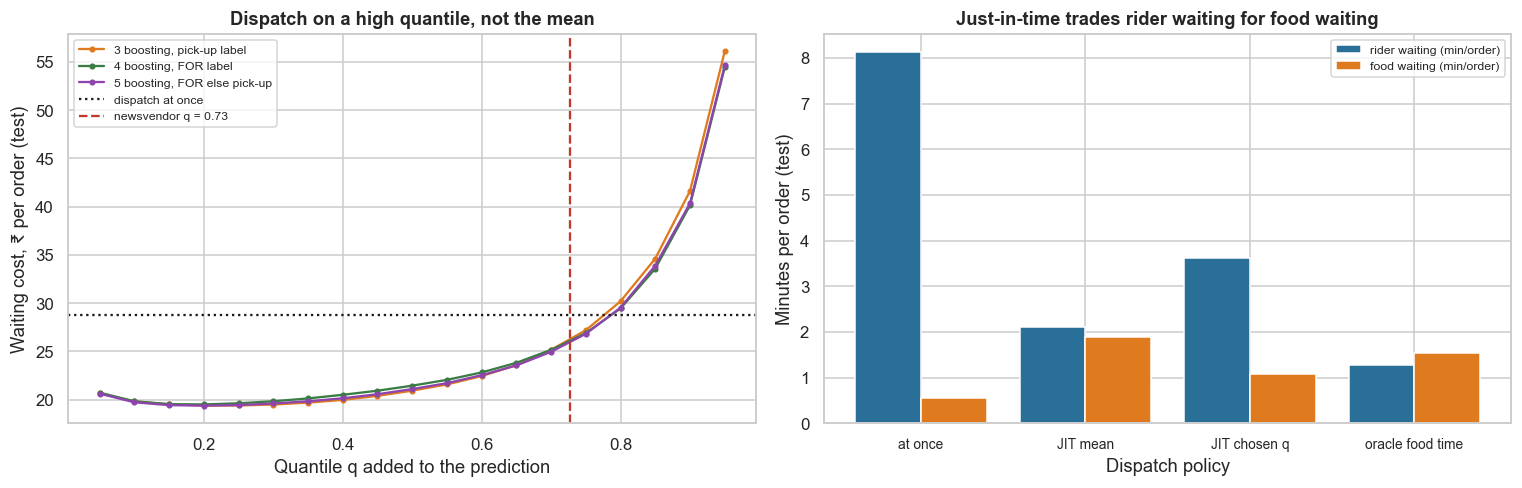

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for k, c in ((K3, "#e07a1f"), (K4, "#3a7d44"), (K5, "#8e44ad")): axes[0].plot(QS, CURVE[k][1], "o-", color=c, ms=3, label=k)
axes[0].axhline(asap[2].mean(), color="k", ls=":", label="dispatch at once"); axes[0].axvline(CF / (CF + CR), color="#c0392b", ls="--", label=f"newsvendor q = {CF / (CF + CR):.2f}")
axes[0].set_xlabel("Quantile q added to the prediction"); axes[0].set_ylabel("Waiting cost, ₹ per order (test)"); axes[0].set_title("Dispatch on a high quantile, not the mean"); axes[0].legend(fontsize=8)
names = ["dispatch at once", "just-in-time on the mean (q = 0.5)", f"just-in-time at chosen q = {QSTAR[KB]:.2f}", "oracle food time, estimated first mile"]; xx = np.arange(len(names))
axes[1].bar(xx - 0.2, [pol[n][0].mean() for n in names], 0.4, color="#2a6f97", label="rider waiting (min/order)"); axes[1].bar(xx + 0.2, [pol[n][1].mean() for n in names], 0.4, color="#e07a1f", label="food waiting (min/order)")
axes[1].set_xticks(xx); axes[1].set_xticklabels(["at once", "JIT mean", "JIT chosen q", "oracle food time"], fontsize=9); axes[1].set_xlabel("Dispatch policy"); axes[1].set_ylabel("Minutes per order (test)"); axes[1].set_title("Just-in-time trades rider waiting for food waiting"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** «O77»

### 7.8 What would an experiment need? Sample size with clustering

**(a) Why?** Orders from the same restaurant on the same day are not independent (kitchen load, rider supply). A realistic test randomises **restaurant-days** (a switchback, as in Case 19), so we estimate the **intra-cluster correlation** of per-order cost, inflate the sample size by the design effect 1 + (m − 1) ICC, and show the sample needed to detect 100%, 50% and 25% of the simulated saving (80% power, α = 0.05, two-sided).

#### Code

In [15]:
c0 = asap[2]; cl = (tt_.restaurant_id.values * 100 + tt_.day.values); g = pd.Series(c0).groupby(cl); k_, N_ = g.ngroups, len(c0); ni = g.size().values; mi = g.mean().values; gm_ = c0.mean()
m0 = (N_ - (ni ** 2).sum() / N_) / (k_ - 1); msb = (ni * (mi - gm_) ** 2).sum() / (k_ - 1); msw = ((c0 - g.transform("mean").values) ** 2).sum() / (N_ - k_); icc = max(0.0, (msb - msw) / (msb + (m0 - 1) * msw)); deff = 1 + (ni.mean() - 1) * icc
sd0 = c0.std(); rows = []
for share in (1.0, 0.5, 0.25):
    dlt = SAV["saving vs at once ₹/order"] * share; n_arm = int(np.ceil(2 * (1.96 + 0.84) ** 2 * sd0 ** 2 / dlt ** 2)); rows.append((f"{share:.0%} of simulated saving", dlt, n_arm, int(np.ceil(n_arm * deff)), int(np.ceil(n_arm * deff / ni.mean()))))
ss = pd.DataFrame(rows, columns=["effect to detect", "₹/order", "orders per arm (independent)", "orders per arm (clustered)", "restaurant-days per arm"]).set_index("effect to detect")
print(f"Per-order cost under dispatch-at-once: mean ₹{c0.mean():.2f}, sd ₹{sd0:.2f}; restaurant-day clusters {k_:,}, mean size {ni.mean():.1f}; ICC {icc:.3f}; design effect {deff:.2f}; share of orders with zero waiting cost: {(c0 == 0).mean():.1%}")
ss.round(3)

Per-order cost under dispatch-at-once: mean ₹28.81, sd ₹22.51; restaurant-day clusters 2,342, mean size 10.6; ICC 0.246; design effect 3.36; share of orders with zero waiting cost: 0.0%


,₹/order,orders per arm (independent),orders per arm (clustered),restaurant-days per arm
effect to detect,,,,
100% of simulated saving,9.278,93,313,30
50% of simulated saving,4.639,370,1245,118
25% of simulated saving,2.320,1477,4970,469


**Observation:** «O78»

## 8. ML Section — what we built and what is beyond it

- **What we built:** a tabular gradient-boosting regressor with restaurant, dish, and kitchen-state features, plus ridge and simple baselines. The point is the **label and the loss**, not model sophistication: the same features give different truth-accuracy depending on the target, and the dispatch cost depends on the quantile used.
- **Beyond this notebook (documented at Zomato):** Word2Vec item embeddings, entity embeddings for restaurants, and a stacked LSTM over the last 5 completed and up to 5 running orders. Our `last5_mean` and `running_orders` features are a crude summary of the same information. Zomato also names reinforcement-style online updating from live restaurant errors as the next step.
- **Beyond this notebook (modelling choices):** train **directly for the quantile** (quantile loss) or use conformal intervals instead of adding residual quantiles; model the first mile jointly; correct the pick-up label by treating it as **censored** (survival-style) rather than discarding it.
- **No tuning** (per the brief): 200 trees, learning rate 0.1, ridge alpha 10, and quantile grid in steps of 0.05 are fixed defaults.

## 9. Business Translation — ₹ impact

Assumptions (D-2-07): **5 lakh orders a day** in the covered cities (illustrative, not a company figure); rider waiting ₹3 a minute and food waiting ₹8 a minute; the saving per order is the simulated test saving of just-in-time dispatch at the chosen quantile over dispatch-at-once, with its bootstrap interval. Real-world friction (riders rejecting a delayed assignment, swaps that do not work, restaurants that do not press FOR) is modelled as a **realisation factor**: worst 40%, base 70%, best 100% of the simulated saving. The label-fix line uses the extra saving of the FOR-trained model over the pick-up-trained model.

#### Code

In [16]:
ORD = 5e5; sav, lo, hi = SAV["saving vs at once ₹/order"], SAV["CI low"], SAV["CI high"]; lf = d43.mean(); lfl, lfh = np.percentile(bs43, 2.5), np.percentile(bs43, 97.5)
def cr_(x): return x * ORD * 365 / 1e7
money = pd.DataFrame({"worst (40%, CI low)": {"JIT dispatch ₹ crore/year": cr_(lo * 0.4), "label fix (FOR) ₹ crore/year": cr_(lfl * 0.4)}, "base (70%, mean)": {"JIT dispatch ₹ crore/year": cr_(sav * 0.7), "label fix (FOR) ₹ crore/year": cr_(lf * 0.7)},
                      "best (100%, CI high)": {"JIT dispatch ₹ crore/year": cr_(hi), "label fix (FOR) ₹ crore/year": cr_(lfh)}}).T
money["total ₹ crore/year"] = money.sum(axis=1)
rwm = pol_t.iloc[0]["rider wait min/order"] - pol_t.iloc[2]["rider wait min/order"]; print(f"Rider waiting avoided: {rwm:.2f} min/order = {rwm * ORD / 60 / 1e3:,.0f} thousand rider-hours/day at 5 lakh orders (before realisation factor); food waiting added: {pol_t.iloc[2]['food wait min/order'] - pol_t.iloc[0]['food wait min/order']:+.2f} min/order")
print(f"Runtime so far: {(time.time() - T_START) / 60:.1f} min"); money.round(2)

Rider waiting avoided: 4.51 min/order = 38 thousand rider-hours/day at 5 lakh orders (before realisation factor); food waiting added: +0.53 min/order
Runtime so far: 13.8 min


,JIT dispatch ₹ crore/year,label fix (FOR) ₹ crore/year,total ₹ crore/year
"worst (40%, CI low)",65.900,-1.290,64.600
"base (70%, mean)",118.530,-1.710,116.820
"best (100%, CI high)",173.960,-1.670,172.290


**Takeaway (business reading):** «O9»

## 10. Recommendation and Decision

«O10»

## 11. Risks, Limitations and Next Steps

- **Simulated truth:** the true food-ready time, rider first-mile and the size of the label contamination were assumed. On real data the true time is **never observed**; the FOR button is itself a noisy proxy and some restaurants press at pick-up. Calibrate the contamination from the share of FOR presses that coincide with pick-up.
- **Cost rates are assumptions:** ₹3 and ₹8 a minute set the best quantile. A change in the cost ratio moves the best q; re-derive it from real rider payout, idle time and customer-lateness effects.
- **Dispatch friction not modelled:** riders may reject an assignment made late, a delayed assignment may find no rider free, and swapping assignments (Swiggy's refinement) changes the economics. We model only the waiting cost of one order in isolation, not rider supply across orders.
- **Selection in FOR:** FOR-labelled orders under-represent busy kitchens; a FOR-only model can fail where it matters most. Use inverse-propensity weights or the hybrid label and monitor busy-kitchen error.
- **Feature timing:** the last-5 history uses labels of orders that may not have finished at prediction time; a live system must use only completed orders.
- **Feedback loop:** a prediction used for dispatch changes the pick-up label itself (the rider now arrives close to the predicted time), which is another reason to trust FOR or a censored-label model rather than the pick-up time.
- **Next steps:** quantile or conformal training; censored-label modelling; restaurant-level online updating (documented as Zomato's next step); a switchback test of JIT dispatch on a few cities with a guard-rail on food waiting and customer complaints.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Pick-up label | max(food ready, rider arrival) + handover |
| Rider wait / food wait | max(0, ready − arrival) / max(0, arrival − ready) |
| Just-in-time delay | max(0, predicted prep time − estimated first-mile time) |
| Waiting cost | CR × rider wait + CF × food wait (₹3 and ₹8 per minute here) |
| Newsvendor quantile | q* = CF / (CF + CR) |
| MAE / RMSE | mean absolute error / square root of mean squared error |
| Within-5 accuracy | share of orders with absolute error of at most 5 minutes |
| Design effect | 1 + (m − 1) × ICC, m = mean orders per cluster |
| McNemar | test on orders where exactly one model is within 5 minutes |

| Term | Meaning |
|---|---|
| FPT | Food preparation time: from acceptance to food ready |
| FOR | "Food Order Ready" button pressed by the restaurant |
| Censored label | A label that only tells you the true value is at most (or at least) what was recorded |
| First mile | Rider assignment plus travel from the rider's position to the restaurant |
| Just-in-time dispatch | Sending the rider so that arrival time matches food-ready time |
| Newsvendor | Choosing a quantity (here a time) when over- and under-shooting cost different amounts |
| Switchback | An experiment that alternates treatment over time blocks (here restaurant-days) |